In [1]:


import os, random, copy, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
MAX_EPOCHS = 60
SEEDS = [21, 42, 123]
NUM_WORKERS = 2 if os.name != "nt" else 0
DATA_DIR = "./data"

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

print("Device:", DEVICE)


Device: cuda


In [2]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

MEAN = (0.4914, 0.4822, 0.4465)
STD  = (0.2470, 0.2435, 0.2616)

plain_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

geometric_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(25),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

photometric_transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.20),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

geo_photo_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.20),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

full_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.20),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.5, scale=(0.15, 0.27), ratio=(0.5, 2.0), value=0)
])


In [3]:
train_raw = datasets.CIFAR10(root=DATA_DIR, train=True, download=True, transform=None)
test_raw = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=None)
selection_rng = np.random.default_rng(2026)
targets = np.asarray(train_raw.targets)
selected_indices = []
for cls in range(10):
    cls_indices = np.flatnonzero(targets == cls)
    selected_indices.extend(selection_rng.choice(cls_indices, size=50, replace=False).tolist())
selected_indices = np.asarray(selected_indices)
selection_rng.shuffle(selected_indices)

split_rng = np.random.default_rng(2027)
train_indices, val_indices = [], []
for cls in range(10):
    idx = selected_indices[targets[selected_indices] == cls].copy()
    split_rng.shuffle(idx)
    train_indices.extend(idx[:40].tolist())
    val_indices.extend(idx[40:].tolist())

print("train_small:", len(selected_indices), "images (50/class)")
print("train:", len(train_indices), "images (40/class)")
print("validation:", len(val_indices), "images (10/class)")
print("clean test:", len(test_raw), "images")

class CIFARSubset(Dataset):
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, list(indices), transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        image, label = self.base[self.indices[i]]
        if self.transform:
            image = self.transform(image)
        return image, label

clean_test_ds = CIFARSubset(test_raw, range(len(test_raw)), plain_transform)
clean_test_loader = DataLoader(clean_test_ds, batch_size=128, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))

def make_loaders(seed, augmentation="none"):
    transform_map = {
        "none": plain_transform,
        "geometric": geometric_transform,
        "photometric": photometric_transform,
        "geo_photo": geo_photo_transform,
        "cutout": full_transform,
        "mixup": full_transform,
        "final": full_transform,
    }
    train_tf = transform_map[augmentation]
    train_ds = CIFARSubset(train_raw, train_indices, train_tf)
    val_ds = CIFARSubset(train_raw, val_indices, plain_transform)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              generator=generator, num_workers=NUM_WORKERS,
                              pin_memory=(DEVICE.type == "cuda"))
    val_loader = DataLoader(val_ds, batch_size=128, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
    return train_loader, val_loader


100%|██████████| 170M/170M [37:21<00:00, 76.1kB/s]


train_small: 500 images (50/class)
train: 400 images (40/class)
validation: 100 images (10/class)
clean test: 10000 images


In [4]:
class ShiftedCIFAR(Dataset):
    def __init__(self, base):
        self.base = base
    def __len__(self):
        return len(self.base)
    def __getitem__(self, idx):
        image, label = self.base[idx]
        rng = random.Random(900000 + idx)
        angle = rng.uniform(-25, 25)
        image = TF.rotate(image, angle)
        brightness = rng.uniform(0.65, 1.35)
        contrast = rng.uniform(0.65, 1.35)
        image = TF.adjust_brightness(image, brightness)
        image = TF.adjust_contrast(image, contrast)


        x0 = rng.randint(0, 16)
        y0 = rng.randint(0, 16)
        image = image.copy()
        arr = np.array(image)
        arr[y0:y0+16, x0:x0+16, :] = 0
        from PIL import Image
        image = Image.fromarray(arr)

        image = plain_transform(image)
        return image, label

def apply_hidden_corruption(image, idx):

    raise NotImplementedError("Instructor's hidden-corruption specification has not been provided.")

shifted_test_ds = ShiftedCIFAR(test_raw)
shifted_test_loader = DataLoader(shifted_test_ds, batch_size=128, shuffle=False,
                                 num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))


In [5]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, c1, c3red, c3, c5red, c5, pool_proj):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(in_ch, c1, 1, bias=False),
                                nn.BatchNorm2d(c1), nn.ReLU(inplace=True))
        self.b3 = nn.Sequential(nn.Conv2d(in_ch, c3red, 1, bias=False),
                                nn.BatchNorm2d(c3red), nn.ReLU(inplace=True),
                                nn.Conv2d(c3red, c3, 3, padding=1, bias=False),
                                nn.BatchNorm2d(c3), nn.ReLU(inplace=True))
        self.b5 = nn.Sequential(nn.Conv2d(in_ch, c5red, 1, bias=False),
                                nn.BatchNorm2d(c5red), nn.ReLU(inplace=True),
                                nn.Conv2d(c5red, c5, 5, padding=2, bias=False),
                                nn.BatchNorm2d(c5), nn.ReLU(inplace=True))
        self.bp = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1),
                                nn.Conv2d(in_ch, pool_proj, 1, bias=False),
                                nn.BatchNorm2d(pool_proj), nn.ReLU(inplace=True))
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)

class SmallInceptionCNN(nn.Module):
    def __init__(self, dropout=0.25):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.inc1 = InceptionBlock(32, 16, 8, 16, 4, 8, 8)  # 48 channels
        self.down1 = nn.Sequential(nn.Conv2d(48, 64, 3, stride=2, padding=1, bias=False),
                                   nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.inc2 = InceptionBlock(64, 24, 12, 24, 6, 12, 12) # 72 channels
        self.down2 = nn.Sequential(nn.Conv2d(72, 96, 3, stride=2, padding=1, bias=False),
                                   nn.BatchNorm2d(96), nn.ReLU(inplace=True))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(96, 10)
    def forward(self, x):
        x = self.stem(x)
        x = self.inc1(x)
        x = self.down1(x)
        x = self.inc2(x)
        x = self.down2(x)
        x = self.pool(x).flatten(1)
        return self.fc(self.dropout(x))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

_tmp = SmallInceptionCNN()
print("Trainable parameters:", f"{count_parameters(_tmp):,}")
assert count_parameters(_tmp) < 1_000_000
del _tmp


Trainable parameters: 103,326


In [6]:
def accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x).argmax(1)
            correct += (pred == y).sum().item()
            total += y.numel()
    return correct / total

def train_one(model, train_loader, val_loader, seed, use_mixup=False, epochs=MAX_EPOCHS):
    set_seed(seed)
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    history = {"train_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state, best_epoch = -1, None, 0
    patience, no_improve = 10, 0

    for epoch in range(epochs):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)

            if use_mixup:
                lam = np.random.beta(0.4, 0.4)
                index = torch.randperm(x.size(0), device=DEVICE)
                mixed_x = lam * x + (1 - lam) * x[index]
                logits = model(mixed_x)
                loss = lam * criterion(logits, y) + (1-lam) * criterion(logits, y[index])
            else:
                logits = model(x)
                loss = criterion(logits, y)

            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.numel()

        scheduler.step()
        train_loss = loss_sum / total
        train_acc = correct / total
        val_acc = accuracy(model, val_loader)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val:
            best_val, best_epoch = val_acc, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    return model, history, best_epoch, best_val

def evaluate_predictions(model, loader):
    model.eval()
    all_y, all_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(DEVICE))
            all_pred.extend(logits.argmax(1).cpu().numpy().tolist())
            all_y.extend(y.numpy().tolist())
    return np.asarray(all_y), np.asarray(all_pred)


## Part A  Baseline

Baseline seed 21
Baseline seed 42
Baseline seed 123


,seed,best_epoch,train_acc_last,val_acc,clean_test_acc,shifted_visible_acc
0,21,17,1.0000,0.45,0.3617,0.2056
1,42,8,0.9975,0.46,0.3599,0.1978
2,123,11,1.0000,0.50,0.3711,0.1594


,seed,best_epoch,train_acc_last,val_acc,clean_test_acc,shifted_visible_acc
mean,62.000000,12.000000,0.999167,0.470000,0.364233,0.187600
std,53.860932,4.582576,0.001443,0.026458,0.006014,0.024731


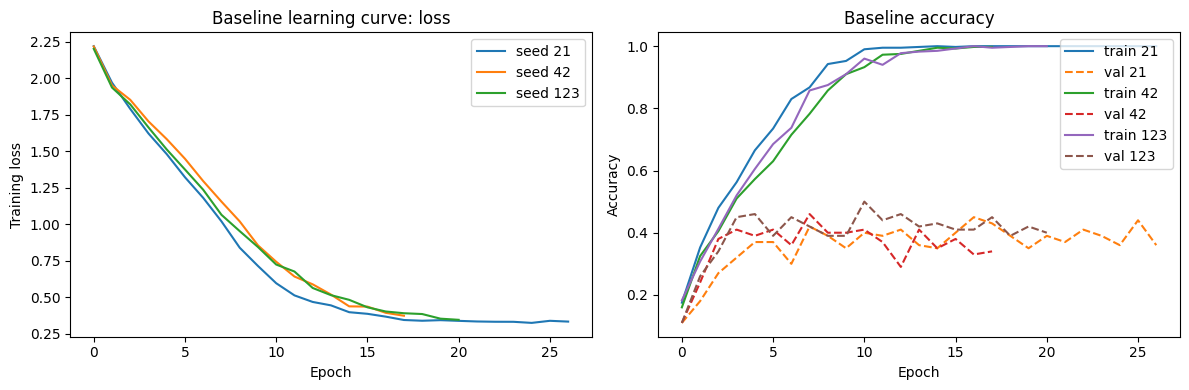

In [7]:
baseline_results = []
baseline_histories = []
baseline_models = {}

for seed in SEEDS:
    print(f"Baseline seed {seed}")
    train_loader, val_loader = make_loaders(seed, "none")
    model, hist, best_epoch, val_acc = train_one(
        SmallInceptionCNN(), train_loader, val_loader, seed, use_mixup=False
    )
    clean_acc = accuracy(model, clean_test_loader)

    shifted_acc = accuracy(model, shifted_test_loader)
    baseline_models[seed] = model
    baseline_histories.append(hist)
    baseline_results.append({
        "seed": seed, "best_epoch": best_epoch, "train_acc_last": hist["train_acc"][-1],
        "val_acc": val_acc, "clean_test_acc": clean_acc, "shifted_visible_acc": shifted_acc
    })

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df)
display(baseline_df.select_dtypes(include=np.number).agg(["mean", "std"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seed, hist in zip(SEEDS, baseline_histories):
    axes[0].plot(hist["train_loss"], label=f"seed {seed}")
    axes[1].plot(hist["train_acc"], label=f"train {seed}")
    axes[1].plot(hist["val_acc"], linestyle="--", label=f"val {seed}")
axes[0].set_title("Baseline learning curve: loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Training loss"); axes[0].legend()
axes[1].set_title("Baseline accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()


In [8]:
ABLATIONS = [
    ("No augmentation", "none", False),
    ("Geometric only", "geometric", False),
    ("Photometric only", "photometric", False),
    ("Geometric + photometric", "geo_photo", False),
    ("+ Cutout / Random Erasing", "cutout", False),
    ("+ Mixup + label smoothing", "mixup", True),
    ("Final model", "final", True),
]


ablation_rows = []
ablation_histories = {}
ablation_models = {}

for config_name, aug_name, mixup_on in ABLATIONS:
    for seed in SEEDS:
        print(f"Training: {config_name}, seed={seed}")
        train_loader, val_loader = make_loaders(seed, aug_name)
        model, hist, best_epoch, val_acc = train_one(
            SmallInceptionCNN(), train_loader, val_loader, seed,
            use_mixup=mixup_on
        )
        clean_acc = accuracy(model, clean_test_loader)
        shifted_acc = accuracy(model, shifted_test_loader)
        ablation_rows.append({
            "configuration": config_name, "seed": seed, "best_epoch": best_epoch,
            "val_acc": val_acc, "clean_test_acc": clean_acc,
            "shifted_visible_acc": shifted_acc
        })
        ablation_histories[(config_name, seed)] = hist
        ablation_models[(config_name, seed)] = copy.deepcopy(model).cpu()

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)
summary_df = (ablation_df.groupby("configuration")
              .agg(val_mean=("val_acc", "mean"), val_std=("val_acc", "std"),
                   clean_mean=("clean_test_acc", "mean"), clean_std=("clean_test_acc", "std"),
                   shifted_mean=("shifted_visible_acc", "mean"),
                   shifted_std=("shifted_visible_acc", "std"))
              .reset_index())
display(summary_df)


Training: No augmentation, seed=21
Training: No augmentation, seed=42
Training: No augmentation, seed=123
Training: Geometric only, seed=21
Training: Geometric only, seed=42
Training: Geometric only, seed=123
Training: Photometric only, seed=21
Training: Photometric only, seed=42
Training: Photometric only, seed=123
Training: Geometric + photometric, seed=21
Training: Geometric + photometric, seed=42
Training: Geometric + photometric, seed=123
Training: + Cutout / Random Erasing, seed=21
Training: + Cutout / Random Erasing, seed=42
Training: + Cutout / Random Erasing, seed=123
Training: + Mixup + label smoothing, seed=21
Training: + Mixup + label smoothing, seed=42
Training: + Mixup + label smoothing, seed=123
Training: Final model, seed=21
Training: Final model, seed=42
Training: Final model, seed=123


,configuration,seed,best_epoch,val_acc,clean_test_acc,shifted_visible_acc
0,No augmentation,21,10,0.42,0.3663,0.1932
1,No augmentation,42,12,0.48,0.3333,0.1857
2,No augmentation,123,11,0.41,0.3592,0.1585
3,Geometric only,21,57,0.53,0.4059,0.2865
4,Geometric only,42,29,0.53,0.3927,0.2769
5,Geometric only,123,8,0.43,0.3339,0.2593
6,Photometric only,21,8,0.44,0.3774,0.2147
7,Photometric only,42,17,0.44,0.3480,0.2004
8,Photometric only,123,12,0.43,0.3546,0.1928
9,Geometric + photometric,21,38,0.49,0.4208,0.2832


,configuration,val_mean,val_std,clean_mean,clean_std,shifted_mean,shifted_std
0,+ Cutout / Random Erasing,0.480000,0.036056,0.370933,0.019164,0.290233,0.008622
1,+ Mixup + label smoothing,0.450000,0.045826,0.367667,0.022905,0.251967,0.013373
2,Final model,0.463333,0.040415,0.383867,0.018309,0.296833,0.016253
3,Geometric + photometric,0.473333,0.020817,0.376500,0.044603,0.262633,0.018266
4,Geometric only,0.496667,0.057735,0.377500,0.038331,0.274233,0.013795
5,No augmentation,0.436667,0.037859,0.352933,0.017370,0.179133,0.018258
6,Photometric only,0.436667,0.005774,0.360000,0.015426,0.202633,0.011120


              precision    recall  f1-score   support

    airplane     0.3985    0.4180    0.4080      1000
  automobile     0.4400    0.5100    0.4724      1000
        bird     0.2805    0.2710    0.2757      1000
         cat     0.2843    0.2590    0.2711      1000
        deer     0.3298    0.1230    0.1792      1000
         dog     0.2985    0.4740    0.3663      1000
        frog     0.4195    0.4900    0.4520      1000
       horse     0.4248    0.4150    0.4198      1000
        ship     0.5026    0.3910    0.4398      1000
       truck     0.4355    0.4490    0.4421      1000

    accuracy                         0.3800     10000
   macro avg     0.3814    0.3800    0.3726     10000
weighted avg     0.3814    0.3800    0.3726     10000



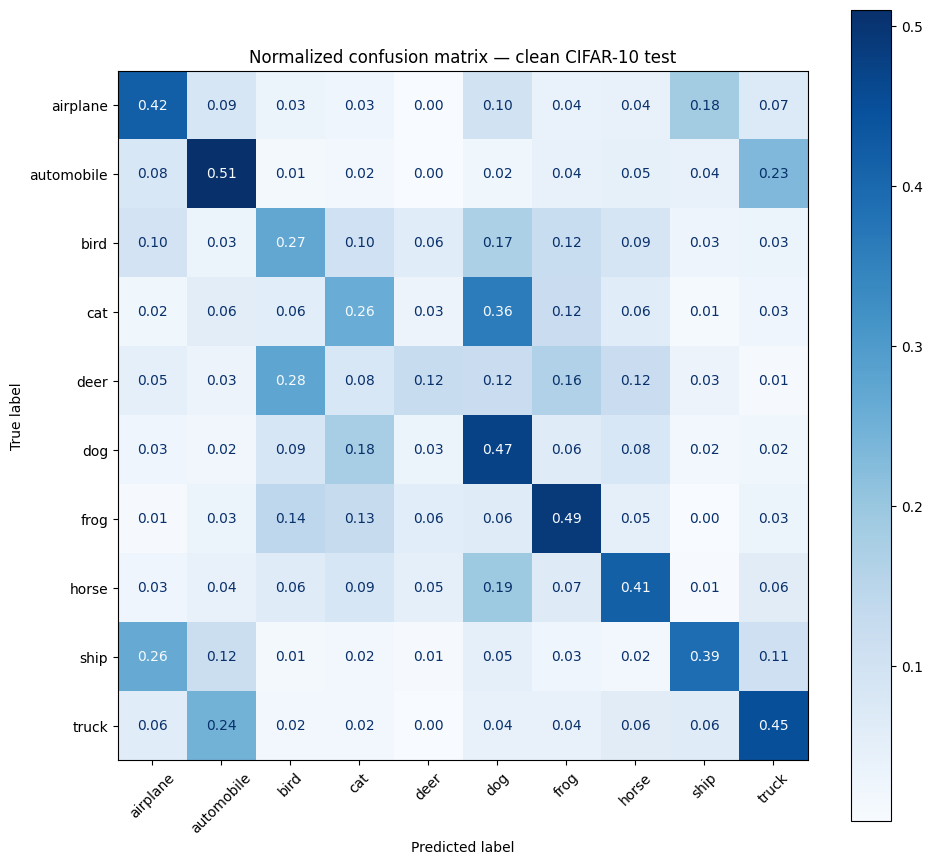

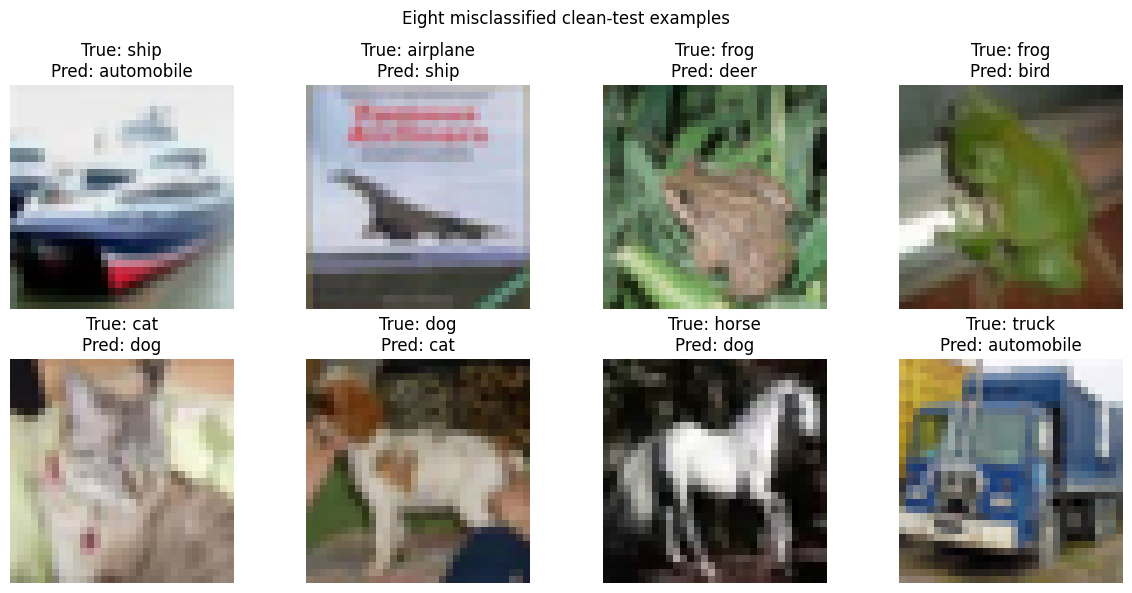

In [9]:

final_model = ablation_models.get(("Final model", 42))
if final_model is None:
    print("Run the ablation cell first to create the final model.")
else:
    final_model = final_model.to(DEVICE)
    y_true, y_pred = evaluate_predictions(final_model, clean_test_loader)
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

    cm = confusion_matrix(y_true, y_pred, normalize="true")
    disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
    fig, ax = plt.subplots(figsize=(10, 9))
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format=".2f", colorbar=True)
    ax.set_title("Normalized confusion matrix — clean CIFAR-10 test")
    plt.tight_layout()
    plt.show()

    mis_idx = np.flatnonzero(y_true != y_pred)[:8]
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, idx in zip(axes.flat, mis_idx):
        img, label = test_raw[int(idx)]
        ax.imshow(img)
        ax.set_title(f"True: {CLASSES[label]}\nPred: {CLASSES[int(y_pred[idx])]}")
        ax.axis("off")
    for ax in axes.flat[len(mis_idx):]:
        ax.axis("off")
    fig.suptitle("Eight misclassified clean-test examples")
    plt.tight_layout()
    plt.show()


In [10]:
def tta_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    start = time.time()
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)
            p1 = torch.softmax(model(x), dim=1)
            p2 = torch.softmax(model(torch.flip(x, dims=[3])), dim=1)
            pred = ((p1 + p2) / 2).argmax(1)
            correct += (pred == y).sum().item()
            total += y.numel()
    elapsed = time.time() - start
    return correct / total, elapsed

if "final_model" in globals() and final_model is not None:
    normal_start = time.time()
    clean_acc_final = accuracy(final_model, clean_test_loader)
    normal_seconds = time.time() - normal_start
    tta_acc, tta_seconds = tta_accuracy(final_model, clean_test_loader)
    print(f"Clean accuracy, no TTA: {clean_acc_final:.4f}")
    print(f"Clean accuracy, flip TTA: {tta_acc:.4f}")
    print(f"Accuracy change: {tta_acc - clean_acc_final:+.4f}")
    print(f"Single-pass evaluation time: {normal_seconds:.2f}s")
    print(f"TTA evaluation time: {tta_seconds:.2f}s")


Clean accuracy, no TTA: 0.3800
Clean accuracy, flip TTA: 0.3801
Accuracy change: +0.0001
Single-pass evaluation time: 3.24s
TTA evaluation time: 3.40s
